# First Naive RDD

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import numpy as np
import statsmodels.api as sm

In [2]:
df_rdd = pd.read_csv('df_rdd_clean.csv')

## Rund first simple RDD

In [3]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,skill_share_pre,skill_share_trend,...,no_diploma_share,skill_share_trend2,far_right_participated,pop_growth,income_median,income_gini,unemployment_rate,foreign_population,share_55plus,share_15_24
0,1053,LUG,437,2014,t1,False,0,-2.409639,0.392705,0.020687,...,0.607295,0.056592,True,-0.001254,17598.333333,0.359431,12.776901,12.083779,32.183521,15.458405
1,1053,LUG,388,2020,t1,False,0,-4.088756,0.428149,0.031427,...,0.571851,NaN,True,0.032115,18158.333333,0.377278,17.997301,13.374704,32.950297,15.156634
2,2168,LDVG,335,2014,t1,False,0,-5.130327,0.345043,0.057388,...,0.654957,0.051668,True,0.006740,17072.666667,0.367293,17.251602,9.679392,30.633696,12.722666
3,2168,LDVC,264,2020,t1,False,0,-5.420827,0.342097,-0.013547,...,0.657903,NaN,True,0.027541,16901.666667,0.382000,22.861113,10.184937,31.172681,12.929002
4,2173,LDVD,315,2014,t2,False,0,-4.599702,0.300207,0.059974,...,0.699793,0.050191,True,-0.041324,15647.333333,0.399986,18.245777,4.982475,31.715797,13.308227
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,95491,LDVD,386,2014,t1,False,0,-8.980798,0.523774,0.058217,...,0.476226,0.098478,True,0.003023,NaN,NaN,6.828629,7.600155,27.334793,11.683627
833,95563,LUMP,411,2014,t1,False,0,-5.092448,0.550017,0.032736,...,0.449983,0.103071,True,0.021183,27897.000000,0.307739,7.879689,9.915605,28.972625,12.799115
834,95607,LUG,344,2008,t1,False,0,-3.158237,0.430999,0.062273,...,0.569001,NaN,True,NaN,22209.000000,0.309100,8.712611,NaN,NaN,NaN
835,95607,LUMP,462,2014,t2,False,0,-3.745754,0.496955,0.041926,...,0.503045,0.086303,True,0.010958,23648.454545,0.301388,9.242316,10.799812,24.812190,12.610730


In [4]:
df_rdd_clean = df_rdd

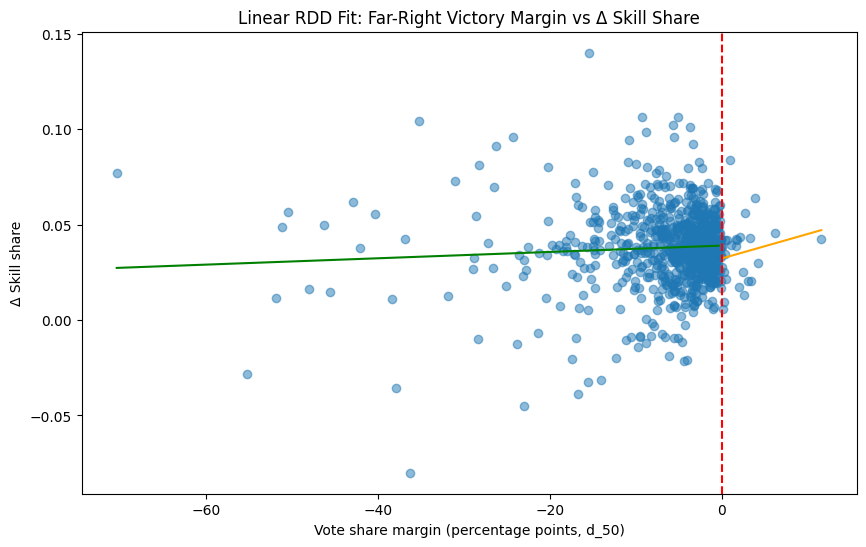

In [5]:
# First simple RDD Plot using matplotlib and statsmodels

# Fit simple linear RDD model (separate slopes each side of cutoff) 
df_rdd_clean['d_50_x_treat'] = df_rdd_clean['d_50'] * df_rdd_clean['treat']
X = sm.add_constant(df_rdd_clean[['d_50', 'treat', 'd_50_x_treat']])
model1 = sm.OLS(df_rdd_clean['delta_skill_share'], X).fit()

# Predict fitted lines on each side of the cutoff 
cutoff = 0.
x_vals = np.linspace(df_rdd_clean['d_50'].min(), df_rdd_clean['d_50'].max(), 200)

x_left = pd.DataFrame({'d_50': x_vals[x_vals <= cutoff], 'treat': 0})
x_left['d_50_x_treat'] = x_left['d_50'] * x_left['treat']
x_left = sm.add_constant(x_left, has_constant='add')

x_right = pd.DataFrame({'d_50': x_vals[x_vals > cutoff], 'treat': 1})
x_right['d_50_x_treat'] = x_right['d_50'] * x_right['treat']
x_right = sm.add_constant(x_right, has_constant='add')

y_pred_left = model1.predict(x_left)
y_pred_right = model1.predict(x_right)

#  Plot 
plt.figure(figsize=(10, 6))
plt.scatter(df_rdd_clean['d_50'], df_rdd_clean['delta_skill_share'], alpha=0.5)
plt.plot(x_left['d_50'], y_pred_left, color='green')
plt.plot(x_right['d_50'], y_pred_right, color='orange')
plt.axvline(cutoff, color='red', linestyle='--')
plt.title('Linear RDD Fit: Far-Right Victory Margin vs Δ Skill Share')
plt.xlabel('Vote share margin (percentage points, d_50)')
plt.ylabel('Δ Skill share')
plt.show()

## Select Bandwidth

In [6]:
from statsmodels.formula.api import ols
from rdrobust import rdbwselect, rdrobust

In [7]:


# Optimal bandwidth selection

# Uses the running variable (d_50) and outcome (delta_skill_share)
# c=0 -> cutoff is at 0 (already centered)
bw_result = rdbwselect(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0
)
print(bw_result)

Call: rdbwselect
Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd     1.272      1.272     2.156      2.156


In [8]:
# RD treatment effect estimation using the selected bandwidth

# rdrobust automatically selects its own optimal bandwidth internally (MSE-optimal by default),
# so you don't strictly need to feed bw_result in manually — but you can inspect/compare
rd_result = rdrobust(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0
)
print(rd_result)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Unique Obs.            811         26
Number of Effective Obs.         106         11
Bandwidth Estimation           1.272      1.272
Bandwidth Bias                 2.156      2.156
rho (h/b)                       0.59       0.59

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.022    0.009   -2.438   1.477e-02    [-0.04, -0.004]
Robust                 -        -   -2.327   1.

In [9]:
# MANUALLY define global variable bw

# Take bw from Diff-in-Disc script

# Restrict sample to the MSE-optimal bandwidth from rdbwselect
bw = 1.285 # h (left) = h (right) from rdbwselect output

In [10]:
df_rdd_bw = df_rdd_clean[
    (df_rdd_clean['d_50'] >= -bw) & (df_rdd_clean['d_50'] <= bw)
].copy()

print(f"N observations within bandwidth: {len(df_rdd_bw)}")
print(f"N treated within bandwidth: {df_rdd_bw['treat'].sum()}")

N observations within bandwidth: 118
N treated within bandwidth: 11


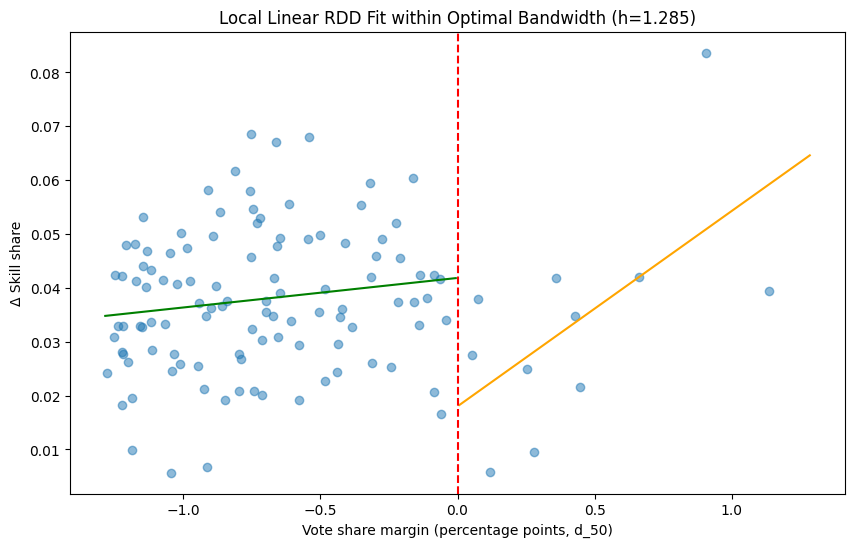

In [11]:
# Fit local linear RDD model within the bandwidth


df_rdd_bw['d_50_x_treat'] = df_rdd_bw['d_50'] * df_rdd_bw['treat']
X = sm.add_constant(df_rdd_bw[['d_50', 'treat', 'd_50_x_treat']])
model_bw = sm.OLS(df_rdd_bw['delta_skill_share'], X).fit()

# Predict fitted lines on each side of the cutoff, within the bandwidth only
cutoff = 0.
x_vals = np.linspace(-bw, bw, 200)

x_left = pd.DataFrame({'d_50': x_vals[x_vals <= cutoff], 'treat': 0})
x_left['d_50_x_treat'] = x_left['d_50'] * x_left['treat']
x_left = sm.add_constant(x_left, has_constant='add')

x_right = pd.DataFrame({'d_50': x_vals[x_vals > cutoff], 'treat': 1})
x_right['d_50_x_treat'] = x_right['d_50'] * x_right['treat']
x_right = sm.add_constant(x_right, has_constant='add')

y_pred_left = model_bw.predict(x_left)
y_pred_right = model_bw.predict(x_right)

#  Plot
plt.figure(figsize=(10, 6))
plt.scatter(df_rdd_bw['d_50'], df_rdd_bw['delta_skill_share'], alpha=0.5)
plt.plot(x_left['d_50'], y_pred_left, color='green')
plt.plot(x_right['d_50'], y_pred_right, color='orange')
plt.axvline(cutoff, color='red', linestyle='--')
plt.title(f'Local Linear RDD Fit within Optimal Bandwidth (h={bw})')
plt.xlabel('Vote share margin (percentage points, d_50)')
plt.ylabel('Δ Skill share')
plt.show()

## Regress naive OLS for RDD

In [12]:
from statsmodels.formula.api import ols

In [13]:
# interaction term: allows the slope of d_50 to differ on each side of the cutoff ──
# Similar the specification in the plot (standard sharp-RDD practice)
model1 = ols('delta_skill_share ~ d_50 * treat', data=df_rdd_clean).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:      delta_skill_share   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     1.469
Date:                Wed, 28 Oct 2026   Prob (F-statistic):              0.221
Time:                        17:39:12   Log-Likelihood:                 2073.9
No. Observations:                 837   AIC:                            -4140.
Df Residuals:                     833   BIC:                            -4121.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0390      0.001     41.876      0.0

In [14]:
# RD point estimate + confidence interval using rdrobust library
rd_result = rdrobust(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0,  # dont know 
    p=1,  # local linear, matches rdplot specification
    h=bw  # my rdwselect bandwidth which I used to restrict the sample for the linear regression above
)
print(rd_result)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   837
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                   Manual
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Unique Obs.            811         26
Number of Effective Obs.         107         11
Bandwidth Estimation           1.285      1.285
Bandwidth Bias                 1.285      1.285
rho (h/b)                        1.0        1.0

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.022    0.009   -2.459   1.394e-02    [-0.04, -0.004]
Robust                 -        -   -1.019   3.

## Using rdrobust library to plot using Bins

In [15]:
from rdrobust import rdplot

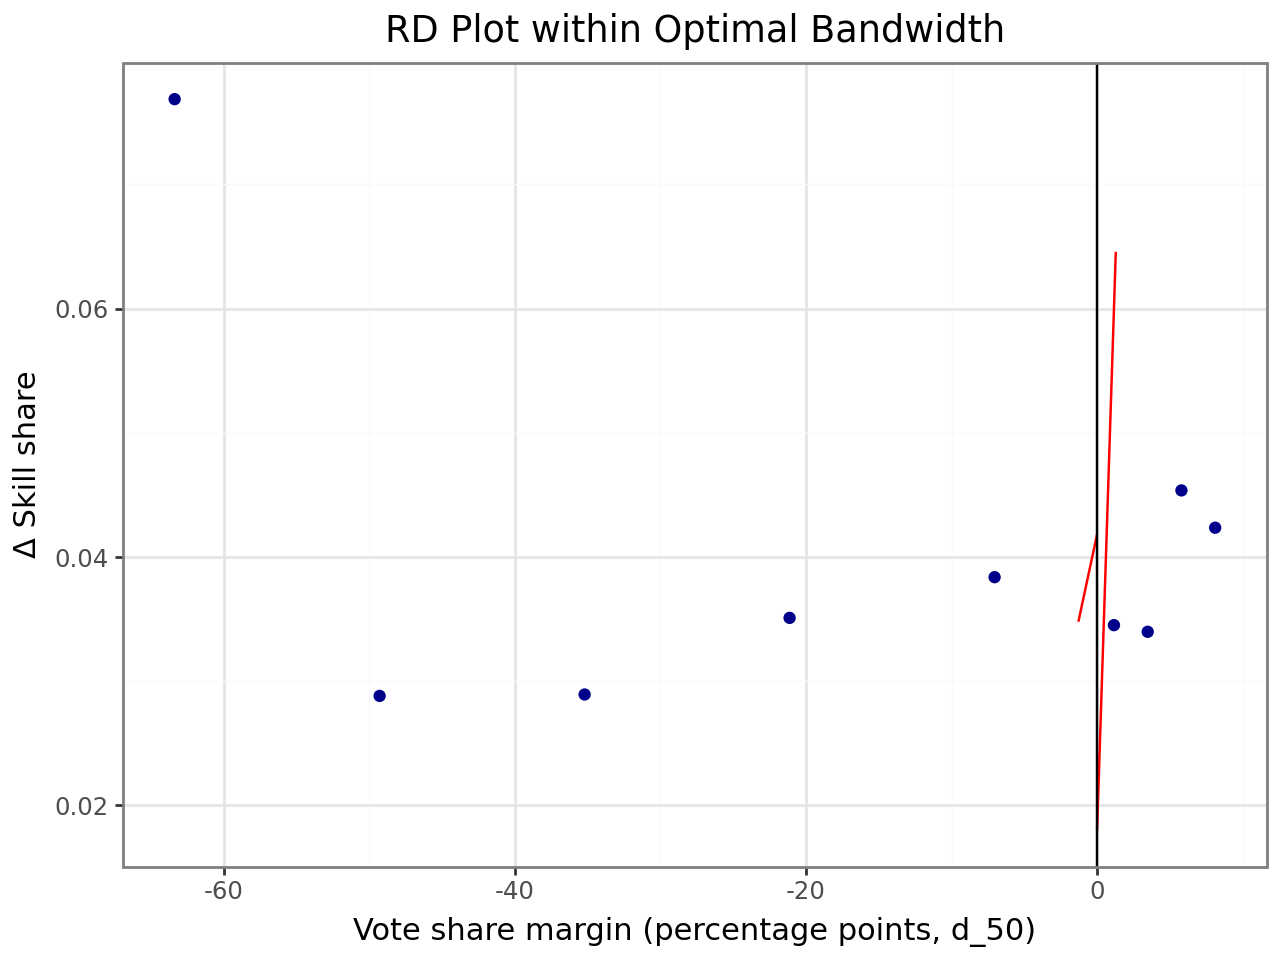

Call: rdplot
Number of Observations:                   837
Kernel:                               Uniform
Polynomial Order Est. (p):                  1

                                Left      Right
------------------------------------------------
Number of Observations           811         26
Number of Effective Obs          107         11
Bandwidth poly. fit (h)        1.285      1.285
Number of bins scale               1          1
Bins Selected                      5          5
Average Bin Length            14.084      2.318
Median Bin Length             14.084      2.318
IMSE-optimal bins                3.0       11.0
Mimicking Variance bins          4.0       30.0

Relative to IMSE-optimal:
Implied scale                  1.667      0.455
WIMSE variance weight          0.178      0.914
WIMSE bias weight              0.822      0.086

In [16]:
# ── Standard rdplot: automatically bins, fits local polynomial, and plots ──
# p=1 -> linear fit (matches your model_bw specification)
# This uses the FULL sample (df_rdd_clean), not just the bandwidth-restricted one --
# rdplot is a descriptive/diagnostic tool and typically shown on the wider sample,
# with the bandwidth from rdbwselect used only for the rdrobust estimation itself
rdplot(
    y=df_rdd_clean['delta_skill_share'],
    x=df_rdd_clean['d_50'],
    c=0,
    p=1,
    h=bw,  # manually restrict to the rdbwselect bandwidth
    nbins=(5, 5),  # 5 bins left, 5 bins right (input from Gabriel)
    title='RD Plot within Optimal Bandwidth',
    x_label='Vote share margin (percentage points, d_50)',
    y_label='Δ Skill share'
)